# V18 at 100 kHz: Rigol pulse-width characterisation and reference calibration

Rigol **CH1 is connected directly to DIO2_P / E1 pin 7**, with common ground.
Use 0–3.3 V pulses. There is no PCB in this test. DIO1_P / E1 pin 5 supplies
the FPGA's internal frame marker / optional scope launch reference; do not
connect two output drivers together. Both Red Pitaya analogue outputs are
turned OFF here; this is separate from the two-weight demonstration.

The target frame and AWG period is **10,000 ns / 100 kHz**. The FPGA launch
stays at 50% duty while Rigol HIGH width changes. Equal programmed frequencies
do not lock the clocks or make the start phase reproducible. The helper may
restart incomplete bursts, and retains every attempt's counts/flags/retry ledger.
Accepted precision/calibration describes selected complete bursts.

This notebook tests DC/signal identity, startup/frame placement, fine correction,
coarse/fine precision, 10 ns width changes, full capacity, drift and residual
width error. It can fit and validate a **host-only** width-reference correction.
It never changes the HDL or silently applies a host correction to raw records.
Qualified same-build V18 LUTs are restored by default; a fresh code-density
calibration near 100 kHz is optional. No 25 MHz tests block this run.

Requires NumPy, Matplotlib, PyVISA and the installed USB VISA runtime. Use the
matching V18 FPGA/API/SCPI server and keep the current FPGA image loaded.


In [12]:
# Single source of configuration; edit before opening the instruments.
RP_IP = "169.254.77.151"
SCPI_PORT = 5000
VISA_RESOURCE = "USB0::0x1AB1::0x0647::DG5R270700006::INSTR"
VISA_BACKEND = ""
AWG_CHANNEL = 1
AWG_SERIAL = "DG5R270700006"
BITSTREAM_LABEL = "v18_20261026_140711"
IMPLEMENTATION_WNS_NS = 0.008

TARGET_HZ = 100_000.0
PERIOD_NS = 10_000
FRAME_OFFSET_NS = 0  # Initial value; 100 kHz offset is not yet qualified.
FRAME_COUNT = 8192
SWEEP_FRAMES = 4096
HOST_TIMEOUT_S = 30.0
REPEATS = 3
PHASE_RETRIES = True   # Every rejected start is retained in compact metadata.
MAX_STARTS = 50        # Bounded; acceptance is completeness only, never width error.

RUN_OFFSET_SCREEN = False  # Optional small screen, not all 2,500 legal offsets.
OFFSET_CANDIDATES_NS = list(range(0,10000,1000))
OFFSET_SCREEN_WIDTH_NS = 500.2
OFFSET_SCREEN_REPEATS = 3
MANUAL_OFFSET_NS = None  # Override after inspecting the screen/scope. Never auto-pick by width error.

REBUILD_FINE_LUT = False
# Only used for optional code density: BOTH instruments get each common period.
# Distinct nearby rates and the usual density/CDF gates test phase coverage;
# exact 100 kHz alone does not establish uniform fine-clock coverage.
CAL_FREQUENCIES_HZ = [99_703.0, 99_103.0, 98_303.0]
CAL_ROUNDS = 8
CAL_FRAMES = 8192
PRECISION_WIDTHS_NS = [20.2, 100.2, 500.2, 2000.2]
TRAIN_WIDTHS_NS = [100.2,250.2,500.2,1000.2,2000.2]
VALIDATE_WIDTHS_NS = [150.2,350.2,750.2,1500.2]
STEP_WIDTHS_NS = [480.2,490.2,500.2,510.2,520.2]
REFERENCE_MODEL = "offset"  # Optional "affine" for scale+offset; independent timebase references are preferable.
REFERENCE_OVERRIDES_NS = {}  # {programmed_width_ns: independently_measured_width_ns}; empty means nominal AWG readback.
REFERENCE_MAX_STD_NS = 0.15
REFERENCE_MAX_BLOCK_SPAN_NS = 0.25


## 1. Load helpers and create the result directory

Existing instrument helpers are reused; no socket/VISA session opens in this
cell. Captures go outside the checkout using `REDPITAYA_DATA_DIR` or the usual
machine-local data root. Full raw CSV is saved only for successful complete
bursts; partial/zero attempts retain compact diagnostic metadata.


In [13]:
import copy, hashlib, importlib, json, sys
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt

helper_dir=next((p for p in (Path.cwd(),Path.cwd()/"scpi-tests")
                 if (p/"tdc_rigol_tools.py").is_file()),None)
if helper_dir is None:raise RuntimeError("Start Jupyter in the repository or scpi-tests")
sys.path.insert(0,str(helper_dir.resolve()))
import tdc_rigol_tools, tdc_100khz_tools
importlib.reload(tdc_rigol_tools);importlib.reload(tdc_100khz_tools)
from tdc_rigol_tools import (Bench, RP, save_json, build_candidate, plot_candidate,
    plot_capture, plot_sweep, precision_comparison, fit_width_reference,
    validate_width_reference, signal_identity_check, alignment_survey, plan_matched_period)
from tdc_100khz_tools import restore_bundled_candidate, require_complete, screen_offsets, compact_capture
from local_data import results_directory

BUNDLE_DIR=helper_dir.resolve().parent/"100kHz_demo"
RUN_DIR=results_directory("tdc_rigol_100khz_results")/datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
config=dict(expected_width_version=18,rp_ip=RP_IP,scpi_port=SCPI_PORT,
    visa_resource=VISA_RESOURCE,visa_backend=VISA_BACKEND,awg_channel=AWG_CHANNEL,
    awg_serial=AWG_SERIAL,low_v=0.0,high_v=3.3,bitstream_label=BITSTREAM_LABEL,
    implementation_wns_ns=IMPLEMENTATION_WNS_NS,frame_count=FRAME_COUNT,
    host_timeout_s=HOST_TIMEOUT_S,socket_timeout_s=10.0,visa_timeout_ms=10000,
    awg_command_delay_s=0.02,settle_s=0.1,launch_settle_s=0.1,
    timing_policy="matched_period_v1",frame_offset_ns=FRAME_OFFSET_NS,
    frame_offsets_by_period_ns={},phase_retries=PHASE_RETRIES,
    phase_retry_max_attempts=MAX_STARTS,phase_retry_delay_s=0.2,capture_retention="complete_only")
bench=Bench(config,RUN_DIR)
all_captures=[]

def take(label,width_ns,*,fine=False,frames=SWEEP_FRAMES,frequency_hz=TARGET_HZ):
    """One named measurement; helper handles instrument setup, readout and OFF cleanup."""
    capture=bench.acquire(label,frequency_hz,float(width_ns),frames=frames,fine=fine,
        reference_ns=REFERENCE_OVERRIDES_NS.get(float(width_ns)))
    all_captures.append(capture)
    summary=capture['summary']
    print(label,summary['complete_pulses'],'/',summary['total_frames'],
          'complete; calibrated:',summary['calibrated_pulses'],
          '; mean/SD/error (ns):',summary['all_complete']['mean_ns'],
          summary['all_complete']['std_ns'],summary['all_complete']['error_ns'])
    retry=capture.get('phase_retry')
    if retry:print('Selected start:',retry['attempt'],'; all-start fraction:',retry['complete_fraction_all_attempts'])
    return require_complete(capture,fine=fine)

save_json(RUN_DIR/"test_plan.json",dict(target_hz=TARGET_HZ,period_ns=PERIOD_NS,
    precision_widths_ns=PRECISION_WIDTHS_NS,training_widths_ns=TRAIN_WIDTHS_NS,
    held_out_widths_ns=VALIDATE_WIDTHS_NS,step_widths_ns=STEP_WIDTHS_NS,
    reference_overrides_ns=REFERENCE_OVERRIDES_NS,rebuild_fine_lut=REBUILD_FINE_LUT,
    phase_retries=PHASE_RETRIES,max_starts=MAX_STARTS))
print('Results:',RUN_DIR)
assert plan_matched_period(TARGET_HZ,40)['common_period_ns']==PERIOD_NS==10000
assert not set(TRAIN_WIDTHS_NS)&set(VALIDATE_WIDTHS_NS)


Results: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_100khz_results\20261026T210023_691148Z


## 2. Preflight and DC controls at 100 kHz

Preflight confirms VERSION18, 4 ns ticks, 512 taps and SINGLE. It disables fine
mode initially; upload/activation is a later explicit step. Both FPGA analogue
outputs are parked OFF, because Rigol directly drives the digital TDC input.
DC LOW/HIGH must track the GPIO and must not manufacture complete pulses.


In [14]:
PREFLIGHT=bench.preflight()
rp=RP(RP_IP,SCPI_PORT,10)
try:
    rp.write('OUTPUT1:STATE OFF');rp.write('OUTPUT2:STATE OFF')
finally:
    rp.close()
print(json.dumps(PREFLIGHT,indent=2))
dc_controls=[]
for stimulus in ('dc_low','dc_high'):
    capture=bench.acquire('100k_'+stimulus,TARGET_HZ,500.2,frames=512,stimulus=stimulus)
    dc_controls.append(capture)
    if (not capture['acquisition_ok'] or capture['cleanup_errors'] or
        capture['summary']['complete_pulses'] or not capture['input_gpio']['matched']):
        raise RuntimeError('Resolve DC input tracking before calibration')
save_json(RUN_DIR/'dc_controls.json',[compact_capture(c) for c in dc_controls])


{
  "image": {
    "width_version": 18,
    "tick_ps": 4000,
    "taps": 512,
    "capacity": 16384,
    "bitstream_label": "v18_20261026_140711",
    "implementation_wns_ns": 0.008,
    "association_policy": "shifted_single_frame_v14",
    "minimum_period_ns": 40,
    "diagnostic_stride": 64,
    "diagnostic_capacity": 256
  },
  "input_before_setup": "SINGLE",
  "selected_input": "SINGLE",
  "awg_identity": "RIGOL TECHNOLOGIES,DG5502 Pro,DG5R270700006,00.01.00",
  "original_awg_settings": "\"PULS,+1.000000000000000E+05,+3.300000000000000E+00,+1.650000000000000E+00,+0.000000000000000E+00\"",
  "original_clock_source": "INT"
}


## 3. Optional frame-offset screen, then apply one offset

The default is 0 ns, not a previously calibrated 100 kHz value. If needed,
screen the explicit candidate list on coarse data, with retries disabled.
Every scan is an independent source restart; its ranking mixes offset and
startup phase. Do not treat the first successful offset as a pin-delay
measurement. Choose `MANUAL_OFFSET_NS` after inspection/scope observation.
The widest return pulse must fit entirely within the chosen 10 us frame.


In [15]:
OFFSET_SCREEN=None
if RUN_OFFSET_SCREEN:
    OFFSET_SCREEN=screen_offsets(bench,TARGET_HZ,OFFSET_SCREEN_WIDTH_NS,
        OFFSET_CANDIDATES_NS,frames=512,repeats=OFFSET_SCREEN_REPEATS)
    print(json.dumps(OFFSET_SCREEN['ranking'],indent=2))


In [16]:
# Edit MANUAL_OFFSET_NS here if needed; rerunning this cell does not repeat the screen.
APPLIED_OFFSET_NS=FRAME_OFFSET_NS if MANUAL_OFFSET_NS is None else MANUAL_OFFSET_NS
if type(APPLIED_OFFSET_NS)!=int or APPLIED_OFFSET_NS%4 or not 0<=APPLIED_OFFSET_NS<PERIOD_NS:
    raise ValueError('Offset must be a 4 ns multiple from 0 to 9996 ns')
bench.config['frame_offsets_by_period_ns']={PERIOD_NS:APPLIED_OFFSET_NS}
save_json(RUN_DIR/'applied_frame_offsets.json',dict(offsets_by_period_ns={PERIOD_NS:APPLIED_OFFSET_NS},
    qualification='Candidate for fresh validation at 100 kHz; independent source phase is not locked'))
print('Applied 100 kHz frame offset:',APPLIED_OFFSET_NS,'ns')


Applied 100 kHz frame offset: 0 ns


## 4. Source identity and startup yield at the operating rate

These tests use only 100 kHz. The identity check changes HIGH width and checks
DC LOW. The subsequent starts measure repeatability of frame placement. If
retries are enabled, inspect all-start counts as well as the accepted bursts.
Passing is not a certificate of phase lock or absolute timing accuracy.


In [17]:
IDENTITY,identity_captures=signal_identity_check(bench,frequency_hz=TARGET_HZ,
    frames=1024,widths_ns=[100.2,500.2,2000.2])
all_captures.extend(identity_captures)
if not IDENTITY['passed']:raise RuntimeError('Resolve signal identity: '+str(IDENTITY['errors']))
ALIGNMENT,alignment_captures=alignment_survey(bench,TARGET_HZ,500.2,repeats=4,frames=1024)
all_captures.extend(alignment_captures)
for capture in alignment_captures:require_complete(capture)
print(json.dumps(ALIGNMENT,indent=2))


DC 0 V: 0/1024 complete pulses (expected zero)
identity_width_100.2: source-start attempt 1/50
  1024/1024 complete; accepted
AWG width identity: {'requested_ns': 100.2, 'readback_ns': 100.2, 'measured_ns': 102.40234375, 'complete_pulses': 1024, 'complete_fraction': 1.0, 'expected_complete_fraction': None, 'phase_retry': {'policy': 'restart_until_complete_v1', 'attempt': 1, 'max_attempts': 50, 'ledger_path': 'C:\\Users\\kairan\\RedPitaya_local_data\\RedPitaya_app\\scpi-tests\\tdc_rigol_100khz_results\\20261026T210023_691148Z\\0004_identity_width_100.2_retries.json', 'conditioned_on_complete_burst': True, 'accepted': True, 'complete_fraction_all_attempts': 1.0, 'total_frames_all_attempts': 1024}}
identity_width_500.2: source-start attempt 1/50
  1024/1024 complete; accepted
AWG width identity: {'requested_ns': 500.2, 'readback_ns': 500.2, 'measured_ns': 502.2265625, 'complete_pulses': 1024, 'complete_fraction': 1.0, 'expected_complete_fraction': None, 'phase_retry': {'policy': 'restart_

## 5. Fine LUT setup: restore V18, or optionally rebuild near 100 kHz

Fine tap calibration describes the same carry-chain/input/clock implementation;
it is not inherently a different table at every pulse repetition rate. Restore
the qualified V18 bundle by default, then validate it at 100 kHz below.

If `REBUILD_FINE_LUT=True`, collect code density at several matched periods near
100 kHz, retaining the existing strict validity/coverage/CDF gates. One exact
100 kHz source alone may cover a biased subset of the 4 ns sampling phase.
Do not detune only the AWG or waive missing-code gates to force a candidate.

The bundle restore reconciles the old placeholder label/null WNS with its
manifest, preserving the original metadata and hash in the saved candidate.
The hardware signature and known build label must match. VERSION18 alone is
not a unique implementation identity. Neither path uploads a width-bias offset.


In [18]:
calibration_captures=[]
if REBUILD_FINE_LUT:
    for round_index in range(CAL_ROUNDS):
        for frequency in CAL_FREQUENCIES_HZ:
            calibration_captures.append(take(f'100k_density_r{round_index}_f{frequency:g}',500.2,
                fine=False,frames=CAL_FRAMES,frequency_hz=frequency))
    candidate=build_candidate(calibration_captures,minimum_samples=50000,minimum_bins=32)
    save_json(RUN_DIR/'candidate_luts.json',candidate)
    plot_candidate(candidate);plt.show()
    if not candidate['ready']:raise RuntimeError('LUT qualification failed: '+str(candidate['quality']))
else:
    candidate=restore_bundled_candidate(BUNDLE_DIR,bench.image,BITSTREAM_LABEL)
    save_json(RUN_DIR/'candidate_luts.json',candidate)
bench.upload(candidate)  # Copies/readbacks both tables, then enables fine mode once.
print('LUT upload and fine activation confirmed. Offset is configured separately.')


LUT upload and fine activation confirmed. Offset is configured separately.


## 6. Fresh coarse/fine precision at 100 kHz

Each pair consists of separate fresh bursts; their source phases need not
match. Coarse samples use 4 ns quantization. Fine SD includes source jitter,
input-path noise and drift; a small SD is not a calibrated absolute error.
The library switches coarse/fine activation as requested but never reuploads
the LUT on each capture. It rechecks/reapplies the selected frame offset while
restarting instruments; this is an idempotent configuration check.


In [19]:
precision=[]
for repeat in range(REPEATS):
    for width in PRECISION_WIDTHS_NS:
        coarse=take(f'100k_repeat{repeat}_w{width:g}_coarse',width,fine=False,frames=FRAME_COUNT)
        fine=take(f'100k_repeat{repeat}_w{width:g}_fine',width,fine=True,frames=FRAME_COUNT)
        comparison=precision_comparison(coarse,fine)
        comparison.update(repeat=repeat,requested_width_ns=width)
        precision.append(comparison)
        print(json.dumps(comparison,indent=2))
save_json(RUN_DIR/'100khz_precision.json',precision)


100k_repeat0_w20.2_coarse: source-start attempt 1/50
  8192/8192 complete; accepted
100k_repeat0_w20.2_coarse 8192 / 8192 complete; calibrated: 0 ; mean/SD/error (ns): 23.08251953125 1.6818135271019883 2.8825195312500007
Selected start: 1 ; all-start fraction: 1.0
100k_repeat0_w20.2_fine: source-start attempt 1/50
  8192/8192 complete; accepted
100k_repeat0_w20.2_fine 8192 / 8192 complete; calibrated: 8192 ; mean/SD/error (ns): 23.0675263671875 0.05060138917639823 2.8675263671875015
Selected start: 1 ; all-start fraction: 1.0
{
  "coarse": {
    "n": 8192,
    "mean_ns": 23.08251953125,
    "std_ns": 1.6818135271019883,
    "error_ns": 2.8825195312500007
  },
  "fine": {
    "n": 8192,
    "mean_ns": 23.0675263671875,
    "std_ns": 0.05060138917639823,
    "error_ns": 2.8675263671875015
  },
  "coarse_std_over_fine_std": 33.236509006484525,
  "note": "Same fine-valid eligibility, separate fresh bursts, no host correction. Includes source and input-path noise.",
  "repeat": 0,
  "reques

## 7. Width-transfer calibration and held-out validation

Measure several known widths to expose residual rise/fall-path bias,
width-dependent nonlinearity and possible scale error. Use independently
measured reference widths in `REFERENCE_OVERRIDES_NS` when available. Otherwise
this is an **AWG-readback-referenced** calibration, not traceable timebase
calibration. Threshold crossings also depend on pulse levels and slew rate.

The default model is a constant host offset. `affine` optionally fits scale and
offset, but source/threshold nonlinearity must not be mislabelled clock scale.
Only stable full captures can train the model. Unstable captures are recorded
as exclusions; failure to obtain a model is retained and does not stop the
remaining characterization. Raw FPGA widths/LUTs are never overwritten.
Validation uses separate widths that were not considered for training.


100k_train_w100.2: source-start attempt 1/50
  4096/4096 complete; accepted
100k_train_w100.2 4096 / 4096 complete; calibrated: 4096 ; mean/SD/error (ns): 102.40376904296875 0.11970259188583884 2.2037690429687444
Selected start: 1 ; all-start fraction: 1.0
100k_train_w250.2: source-start attempt 1/50
  4096/4096 complete; accepted
100k_train_w250.2 4096 / 4096 complete; calibrated: 4096 ; mean/SD/error (ns): 252.11211547851562 0.050342136819964266 1.9121154785156023
Selected start: 1 ; all-start fraction: 1.0
100k_train_w500.2: source-start attempt 1/50
  4096/4096 complete; accepted
100k_train_w500.2 4096 / 4096 complete; calibrated: 4096 ; mean/SD/error (ns): 502.20562548828127 0.044761442010375824 2.0056254882812823
Selected start: 1 ; all-start fraction: 1.0
100k_train_w1000.2: source-start attempt 1/50
  4096/4096 complete; accepted
100k_train_w1000.2 4096 / 4096 complete; calibrated: 4096 ; mean/SD/error (ns): 1002.1173071289062 0.30952497364801373 1.917307128906259
Selected star

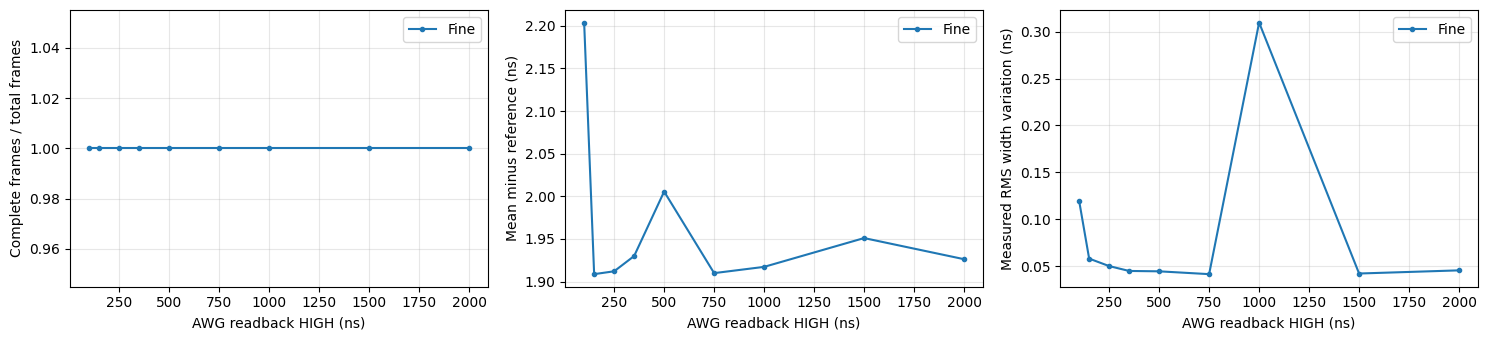

In [20]:
training=[take(f'100k_train_w{width:g}',width,fine=True) for width in TRAIN_WIDTHS_NS]
held_out=[take(f'100k_holdout_w{width:g}',width,fine=True) for width in VALIDATE_WIDTHS_NS]
reference_model=None
reference_validation=[]
reference_fit_error=None
try:
    reference_model=fit_width_reference(training,model=REFERENCE_MODEL,
        minimum_reference_ns=100,maximum_std_ns=REFERENCE_MAX_STD_NS,
        maximum_block_span_ns=REFERENCE_MAX_BLOCK_SPAN_NS)
    reference_validation=validate_width_reference(reference_model,held_out)
except (ValueError,RuntimeError) as exc:
    reference_fit_error=str(exc)
    print('No qualified width-reference model:',exc)
save_json(RUN_DIR/'100khz_width_reference.json',dict(model=reference_model,
    held_out=reference_validation,fit_error=reference_fit_error,
    uploaded_to_fpga=False,absolute_accuracy_qualified=False))
print(json.dumps(dict(model=reference_model,validation=reference_validation),indent=2))
plot_sweep(training+held_out);plt.show()


## 8. Resolve 10 ns width changes; inspect full-capacity drift

The 10 ns step check is separate from fitting. Compare measured adjacent means
and distributions, not only a fitted curve. The largest 16,384-record burst
spans 163.84 ms at 100 kHz; independent-clock phase drift can be more visible
than in the earlier 655 us, 25 MHz burst. Sparse timestamps and block means
help distinguish whole-edge drift from a changing measured width.


100k_step_w480.2: source-start attempt 1/50
  4096/4096 complete; accepted
100k_step_w480.2 4096 / 4096 complete; calibrated: 4096 ; mean/SD/error (ns): 482.19223779296874 0.0478992848286241 1.9922377929687514
Selected start: 1 ; all-start fraction: 1.0
100k_step_w490.2: source-start attempt 1/50
  4096/4096 complete; accepted
100k_step_w490.2 4096 / 4096 complete; calibrated: 4096 ; mean/SD/error (ns): 492.1222458496094 0.04988912598146912 1.9222458496093964
Selected start: 1 ; all-start fraction: 1.0
100k_step_w500.2: source-start attempt 1/50
  2081/4096 complete; saved; restarting sources
100k_step_w500.2: source-start attempt 2/50
  4096/4096 complete; accepted
100k_step_w500.2 4096 / 4096 complete; calibrated: 4096 ; mean/SD/error (ns): 502.189859375 0.044051753889681605 1.9898593750000373
Selected start: 2 ; all-start fraction: 0.7540283203125
100k_step_w510.2: source-start attempt 1/50
  4096/4096 complete; accepted
100k_step_w510.2 4096 / 4096 complete; calibrated: 4096 ; mean

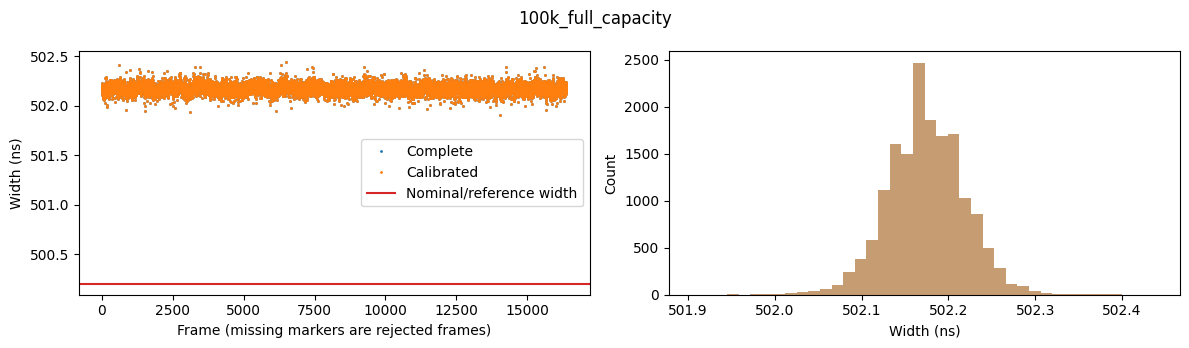

Full-burst edge diagnostics: {
  "valid_pairs": 256,
  "rise_drift": {
    "n": 256,
    "median_ns": -401.5915,
    "min_ns": -802.979,
    "range_ns": 802.979,
    "max_ns": 0.0,
    "p01_ns": -794.9267,
    "p99_ns": -8.022050000000036,
    "beyond_1ns_from_median": 256,
    "block_means_ns": [
      -48.821875,
      -149.62215625000002,
      -250.41096875,
      -351.20321875,
      -451.95743749999997,
      -552.7118437500001,
      -653.45809375,
      -754.20015625
    ],
    "block_mean_span_ns": 705.37828125
  },
  "fall_drift": {
    "n": 256,
    "median_ns": -401.6275,
    "min_ns": -802.983,
    "range_ns": 802.983,
    "max_ns": 0.0,
    "p01_ns": -795.01925,
    "p99_ns": -8.082300000000036,
    "beyond_1ns_from_median": 256,
    "block_means_ns": [
      -48.85365625,
      -149.64615625,
      -250.44140624999997,
      -351.21771875,
      -451.98815625,
      -552.73775,
      -653.494625,
      -754.23775
    ],
    "block_mean_span_ns": 705.38409375
  },
  "widt

In [21]:
step_captures=[take(f'100k_step_w{width:g}',width,fine=True) for width in STEP_WIDTHS_NS]
step_results=[]
for left,right in zip(step_captures,step_captures[1:]):
    requested=right['reference_ns']-left['reference_ns']
    measured=right['summary']['calibrated_only']['mean_ns']-left['summary']['calibrated_only']['mean_ns']
    step_results.append(dict(from_ns=left['reference_ns'],to_ns=right['reference_ns'],
        reference_change_ns=requested,measured_change_ns=measured,error_in_change_ns=measured-requested))
save_json(RUN_DIR/'100khz_10ns_steps.json',step_results)
print(json.dumps(step_results,indent=2))
full_capacity=take('100k_full_capacity',500.2,fine=True,frames=bench.image['capacity'])
plot_capture(full_capacity);plt.show()
print('Full-burst edge diagnostics:',json.dumps({key:full_capacity['edge_diagnostics'][key]
    for key in ('valid_pairs','rise_drift','fall_drift','width_change_distribution')},indent=2))


## 9. Save the 100 kHz profile and stop

The profile contains the candidate LUTs, chosen 100 kHz frame setting, build
identity, compact validation results and any separate host-reference model.
It does **not** replace the original portable V18 bundle or certify absolute
accuracy automatically. Review all attempts, bias and drift before adopting it
for the PCB demonstration. Direct DIO2_P testing does not calibrate the PCB or
the analogue-output voltage-to-weight relationship.


In [22]:
profile=dict(bitstream_label=BITSTREAM_LABEL,image=bench.image,target_hz=TARGET_HZ,
    offset_screen=OFFSET_SCREEN,alignment=ALIGNMENT,signal_identity=IDENTITY,
    candidate=candidate,frame_offsets=dict(offsets_by_period_ns={PERIOD_NS:APPLIED_OFFSET_NS},
        qualification='Observed in selected complete bursts at 100 kHz; independent-source phase lock not established'),
    precision=precision,ten_ns_steps=step_results,width_reference_model=reference_model,
    width_reference_validation=reference_validation,width_reference_fit_error=reference_fit_error,
    captures=[compact_capture(c) for c in all_captures],
    absolute_accuracy_qualified=False,pcb_transfer_calibrated=False,
    note='Review required. Equal frequencies do not lock phase. Host width correction is not uploaded to FPGA.')
save_json(RUN_DIR/'100khz_profile.json',profile)
print('Saved:',RUN_DIR/'100khz_profile.json')
print(bench.stop())


Saved: C:\Users\kairan\RedPitaya_local_data\RedPitaya_app\scpi-tests\tdc_rigol_100khz_results\20261026T210023_691148Z\100khz_profile.json
AWG selected output OFF; FPGA pulse output OFF; width capture idle.


## Stop / recover at any time

Run the next cell after an interrupted stage. Each acquisition already attempts
AWG and FPGA launch OFF/abort in cleanup. A failed network connection can still
prevent shutdown: reconnect and stop before continuing. Do not reload the FPGA
mid-run. If the same image was reloaded, rerun preflight and restore the saved
candidate before fine capture. A different route/input needs new calibration.
This notebook does not drive OUT1/OUT2; they were parked OFF at preflight.


In [23]:
print(bench.stop())


AWG selected output OFF; FPGA pulse output OFF; width capture idle.


## What else needs calibration or qualification?

| Item | Why it matters / what this test establishes |
|---|---|
| Fine RISE/FALL LUTs | Tap-to-time transfer for this route/input; restore or optionally regenerate, then validate at 100 kHz. |
| Frame placement and startup | Put both edges in one frame. Offset is not width correction; unmatched clocks can drift/restart at different phases. |
| Width transfer (bias, scale, nonlinearity) | Compare several reference widths and separate held-out widths. An offset may suffice only over a qualified range. |
| Clock/timebase accuracy | Use an independently verified time reference if absolute ns/ps accuracy is required. AWG readback alone does not measure either oscillator's error. |
| Levels, slew and input threshold | Record/verify pulse levels, rise/fall times and actual waveform at the FPGA pin. Different threshold crossings can change apparent width. This notebook fixes 0/3.3 V stimulus conditions, not a calibrated threshold. |
| Stability versus time/temperature | Repeat starts and long bursts; repeat calibration/verification after material temperature or setup changes. |
| PCB and analogue weights | Later measure DAC voltage gain/offset under the real load, voltage-to-weight mapping, and PCB input/weight-to-pulse-width transfer. Direct AWG-to-DIO testing does not include those paths. |

For the planned ~10 ns demonstration, prioritize complete stable captures and
10 ns step separation over claiming picosecond absolute accuracy. Cable delay
mostly matters for launch-to-return latency/frame placement; unequal rise/fall
propagation and threshold effects can still bias a pulse-width difference.
